In [1]:
import os
import warnings
import folium
import rasterio
import shapely
import cmocean
import math

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import nivapy3 as nivapy
import matplotlib.pyplot as plt
import numpy as np
import contextily as cx

from matplotlib.backends.backend_pdf import PdfPages
from geopandas import GeoSeries
from shapely.geometry import Polygon

plt.style.use("ggplot")
warnings.simplefilter("ignore")

In [2]:
eng = nivapy.da.connect_postgis()

Connection successful.


# User input

In [3]:
# Directory to read raw shapefile from and to write processed shp to
cur_dir = r"/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments"
dem_res = 20  # m

# id col to use throughout
id_col = 'site_code'

# Over this number of samples, the site is classified as high priority (e.g. for manual checking)
n_samps_priority = 9

# Read in delineated catchments and outlet points

## v1 catchments

In [35]:
# Delineated catchments (v1)
cat_gdf_v1 = gpd.read_file(os.path.join(cur_dir, "shp", f"raw_catchments_vm-quant_{dem_res}-dem.shp"))

rename_cols_dict = {
    'WaterLocat': 'site_code',
    'WaterLoc_1': 'site_id',
    'n_years_wi': 'n_years',
    'av_samplin': 'av_freq',
    'area_km2': 'area_km2_v1'
}

cat_gdf_v1 = cat_gdf_v1.drop('samples_pe', axis=1)

cat_gdf_v1 = cat_gdf_v1.rename(columns=rename_cols_dict)
cat_gdf_v1

,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2_v1,geometry
0,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00,1008.505005,"POLYGON ((306680 6664180, 306760 6664180, 3067..."
1,001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00,1009.065359,"POLYGON ((306680 6664180, 306760 6664180, 3067..."
2,001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00,6.702626,"POLYGON ((298520 6555300, 298640 6555300, 2986..."
3,001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17,15.372746,"POLYGON ((290660 6567260, 290680 6567260, 2906..."
4,001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00,42.291160,"POLYGON ((305560 6548480, 305560 6548500, 3055..."
...,...,...,...,...,...,...,...,...,...,...,...,...
10852,314-48346,11.899881,59.758556,48346,"Hornfisktjern, utløp",2011,2022,11.0,3,0.27,0.269215,"POLYGON ((325520 6628880, 325540 6628880, 3255..."
10853,314-62046,11.730778,59.479630,62046,Håbyelva,2012,2012,1.0,2,2.00,1.341151,"POLYGON ((315400 6600460, 315640 6600460, 3156..."
10854,314-89994,11.771138,59.773726,89994,"Store Lyseren, utløp",2011,2011,1.0,1,1.00,3.076772,"POLYGON ((317940 6629100, 317960 6629100, 3179..."
10855,315-48068,11.464094,58.897006,48068,"Årbutjernet, utløp",2011,2011,1.0,1,1.00,0.848219,"POLYGON ((297020 6534660, 297100 6534660, 2971..."


## v2 points

In [36]:
# Read in all the monitoring points left after the first round of cleaning
pt_v2_fpath = os.path.join(cur_dir, "outlet_locations_vm-rivs-quant-oc_v2-full.csv")
pts_v2_df = pd.read_csv(pt_v2_fpath)

# Drop old geometry column (just in case) and make geodataframe of points
pts_v2_df = pts_v2_df.drop('geometry', axis=1)
pts_v2_gdf = gpd.GeoDataFrame(pts_v2_df, geometry=gpd.points_from_xy(pts_v2_df.lon, pts_v2_df.lat), crs="EPSG:4326")
pts_v2_gdf = pts_v2_gdf.to_crs("EPSG:25833")

pts_v2_gdf.head()

,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2_v1,is_lake_raw_v1,dist_to_cb_v1,inside_v1,outside_v1,f_outside_no_v1,min_area_km2,delineate_v2,geometry
0,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00,1008.505005,False,4.570377,False,False,0.009989,0.2,False,POINT (310465.118 6597884.57)
1,001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00,1009.065359,False,22.198387,False,False,0.009983,0.2,False,POINT (310481.985 6597412.97)
2,001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00,6.702626,False,8.430665,False,False,-0.000205,0.2,False,POINT (295802 6553328.19)
3,001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17,15.372746,False,1.650297,False,False,-0.000290,0.2,False,POINT (287981.65 6559432.015)
4,001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00,42.291160,False,5.229977,False,False,-0.000143,0.2,False,POINT (300536.51 6543885.23)


## Catchments updated in v2 delineation

In [37]:
# Result of re-delineation for a subsets of points (delineation v2)
cat_redel_gdf = gpd.read_file(os.path.join(cur_dir, "shp", f"raw_catchments_redelineation_v2_{dem_res}-dem.shp"))

rename_cols_dict = {
    'area_km2_v': 'area_km2_v1',
    'is_lake_ra': 'is_lake_raw_v1',
    'min_area_k': 'min_area_km2'
}

col_drop_li = ['dist_to_cb', 'f_outside_']
cat_redel_gdf = cat_redel_gdf.drop(col_drop_li, axis=1)
cat_redel_gdf = cat_redel_gdf.rename(columns=rename_cols_dict)

pt_redel_gdf = gpd.GeoDataFrame(
    cat_redel_gdf.copy(),
    geometry=gpd.points_from_xy(cat_redel_gdf["lon"], cat_redel_gdf["lat"]),
    crs="EPSG:4326"
)
pt_redel_gdf = pt_redel_gdf.to_crs(cat_redel_gdf.crs)

cat_redel_gdf

,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2_v1,is_lake_raw_v1,inside_v1,outside_v1,min_area_km2,area_km2,geometry
0,087-97589,6.114789,61.820729,97589,Gloppen Andenes,2020,2022,2.5,12,4.82,1.820167,False,False,False,0.00,1.820167,"POLYGON ((32940 6886240, 32960 6886240, 32960 ..."
1,126-64060,11.444429,63.745459,64060,Banemyra skytebane (V-05),2013,2018,5.3,14,2.66,0.303613,False,False,False,0.00,0.001200,"POLYGON ((324580 7073540, 324620 7073540, 3246..."
2,001-38856,11.359621,59.853254,38856,"Viketjenn, utløp",2005,2024,19.0,19,1.00,1.820401,True,True,False,0.05,0.071184,"POLYGON ((295960 6640720, 296080 6640720, 2960..."
3,001-48333,11.489173,58.890788,48333,Svendstjern,2011,2011,1.0,1,1.00,0.227953,False,False,False,0.05,0.227953,"POLYGON ((297500 6533480, 297540 6533480, 2975..."
4,001-48357,11.593958,59.013004,48357,"Åletjern, utløp",2020,2020,1.0,1,1.00,0.201972,False,False,False,0.05,0.196373,"POLYGON ((304620 6547120, 304660 6547120, 3046..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
586,021-122049,7.814550,58.642620,122049,Byglandsfjorden utløp,2015,2024,9.5,46,4.84,0.219642,False,False,False,2000.00,2666.848206,"POLYGON ((73300 6550880, 73320 6550880, 73320 ..."
587,124-104363,10.928191,63.451791,104363,"Værnes, ENVA-SE3",2021,2022,1.2,13,11.02,0.209157,False,False,False,2000.00,2093.107359,"POLYGON ((301040 7030660, 301000 7030660, 3010..."
588,019-86065,8.605386,58.406792,86065,Nidelva ved Lillestø,2023,2023,1.0,23,23.00,0.212642,False,False,False,3000.00,3933.209755,"POLYGON ((115420 6535380, 115420 6535400, 1154..."
589,016-31841,9.647439,59.157717,31841,Skienselva ved Borgestad,1992,2008,16.6,155,9.32,0.920632,False,False,False,10000.00,10688.232251,"POLYGON ((77300 6616140, 77280 6616140, 77280 ..."


In [38]:
# Are there many more tiny catchments now?
cat_redel_gdf.describe()

,lon,lat,site_id,start_year,end_year,n_years,n_samples,av_freq,area_km2_v1,min_area_km2,area_km2
count,591.000000,591.000000,591.000000,591.000000,591.000000,591.000000,591.000000,591.000000,591.000000,591.000000,591.000000
mean,9.536500,60.911284,90116.866328,2017.302876,2020.500846,3.704399,14.527919,3.575364,236.531939,65.685787,302.528568
std,3.055615,2.478664,26084.323988,6.527229,4.648628,5.074066,63.026243,7.440404,2447.651209,616.576513,2221.080348
min,4.693305,58.015685,-3.000000,1985.000000,1995.000000,1.000000,1.000000,0.190000,0.199123,0.000000,0.001200
25%,7.679832,59.485586,66999.000000,2015.000000,2018.000000,1.000000,2.000000,1.000000,0.212350,0.050000,0.090468
50%,9.912209,60.183271,96702.000000,2019.000000,2022.000000,1.000000,4.000000,2.000000,0.260593,0.050000,0.149884
75%,10.762619,61.548158,112210.500000,2022.000000,2024.000000,4.600000,10.000000,4.000000,1.148879,0.050000,0.225079
max,29.938335,70.836943,127357.000000,2025.000000,2026.000000,40.600000,1138.000000,159.000000,40556.928125,10000.000000,40542.103156


## Update v1 of catchments with result of v2 delineation

In [39]:
# Drop v1 delineated catchments that are not present in v2 monitoring points
cat_gdf_v2 = cat_gdf_v1.loc[cat_gdf_v1['site_code'].isin(pts_v2_gdf['site_code'])].copy()
cat_gdf_v2

,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2_v1,geometry
0,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00,1008.505005,"POLYGON ((306680 6664180, 306760 6664180, 3067..."
1,001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00,1009.065359,"POLYGON ((306680 6664180, 306760 6664180, 3067..."
2,001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00,6.702626,"POLYGON ((298520 6555300, 298640 6555300, 2986..."
3,001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17,15.372746,"POLYGON ((290660 6567260, 290680 6567260, 2906..."
4,001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00,42.291160,"POLYGON ((305560 6548480, 305560 6548500, 3055..."
...,...,...,...,...,...,...,...,...,...,...,...,...
10836,313-99151,12.111818,59.990523,99151,Hesbølsjøen utløp,2024,2024,1.0,5,5.00,141.833882,"POLYGON ((330620 6675880, 330820 6675880, 3308..."
10841,314-46646,11.699073,59.634394,46646,"Åkevannet, utløp",2011,2022,11.0,4,0.36,8.233540,"POLYGON ((313080 6620240, 313120 6620240, 3131..."
10842,314-48074,11.924796,59.747409,48074,"Røvatnet, utløp",2011,2011,1.0,1,1.00,34.438479,"POLYGON ((323300 6634700, 323280 6634700, 3232..."
10853,314-62046,11.730778,59.479630,62046,Håbyelva,2012,2012,1.0,2,2.00,1.341151,"POLYGON ((315400 6600460, 315640 6600460, 3156..."


In [40]:
# Update v1 delineations with v2

assert cat_gdf_v1.crs == cat_redel_gdf.crs

cat_gdf_v1 = cat_gdf_v1.set_index(id_col)
cat_gdf_v2 = cat_gdf_v2.set_index(id_col)
cat_redel_gdf = cat_redel_gdf.set_index(id_col)

cat_gdf_v2.update(cat_redel_gdf)

# Add new area col (rather than merging...)
cat_gdf_v2["area_km2"] = cat_gdf_v2.to_crs({"proj": "cea"})["geometry"].area / 1e6

# ------ QA----------------
common_ids = cat_gdf_v1.index.intersection(cat_redel_gdf.index)
print("Number of catchments to overwrite:", len(common_ids))

# Example: check one ID manually
test_id = common_ids[0]

print(cat_gdf_v1.loc[cat_gdf_v1.index == test_id, "geometry"])
print(cat_gdf_v2.loc[cat_gdf_v2.index == test_id, "geometry"])

changed = (
    cat_gdf_v1.loc[common_ids, "geometry"]
    != cat_redel_gdf.loc[common_ids, "geometry"]
)

print("Geometries differing from original:", changed.sum())

cat_gdf_v2 = cat_gdf_v2.reset_index()
cat_gdf_v1 = cat_gdf_v1.reset_index()
cat_redel_gdf = cat_redel_gdf.reset_index()

Number of catchments to overwrite: 591
site_code
001-38856    POLYGON ((296140 6643680, 296200 6643680, 2962...
Name: geometry, dtype: geometry
site_code
001-38856    POLYGON ((295960 6640720, 296080 6640720, 2960...
Name: geometry, dtype: geometry
Geometries differing from original: 455


In [41]:
cat_gdf_v1.describe()

,lon,lat,site_id,start_year,end_year,n_years,n_samples,av_freq,area_km2_v1
count,10857.000000,10857.000000,10857.000000,10857.000000,10857.000000,10857.000000,10857.000000,10857.000000,10857.000000
mean,9.904482,61.048435,76946.894538,2014.665193,2019.189555,5.017583,16.674035,3.358669,286.328611
std,3.479283,2.631746,29682.896958,8.595362,6.870217,6.624304,72.678605,6.669413,1846.229166
min,4.693305,58.015685,-11.000000,1980.000000,1983.000000,1.000000,1.000000,0.060000,0.198919
25%,7.972197,59.491976,50840.000000,2011.000000,2017.000000,1.000000,2.000000,1.000000,1.051199
50%,9.906098,60.165520,83016.000000,2017.000000,2021.000000,1.000000,4.000000,2.000000,4.513914
75%,10.983130,61.527778,102585.000000,2021.000000,2024.000000,7.000000,10.000000,4.000000,28.474989
max,30.952229,70.962425,127364.000000,2025.000000,2026.000000,44.900000,2020.000000,246.040000,41698.296544


In [42]:
# New summary
cat_gdf_v2.describe()

,lon,lat,site_id,start_year,end_year,n_years,n_samples,av_freq,area_km2_v1,area_km2
count,9336.000000,9336.000000,9336.000000,9336.000000,9336.000000,9336.000000,9336.000000,9336.000000,9336.000000,9336.000000
mean,9.878741,61.234493,80902.583655,2015.555484,2019.270673,4.244034,18.516067,3.756606,331.451373,335.628967
std,3.562102,2.718014,29276.766008,8.365686,6.930715,6.053199,78.151473,7.094464,1986.724904,1969.690913
min,4.693305,58.015685,-11.000000,1980.000000,1983.000000,1.000000,1.000000,0.060000,0.199123,0.001200
25%,7.692599,59.572899,58067.750000,2013.000000,2017.000000,1.000000,2.000000,1.000000,1.541705,1.501228
50%,9.947808,60.345965,85741.500000,2018.000000,2021.000000,1.000000,4.000000,2.110000,6.542131,6.536503
75%,10.978972,61.927643,104694.250000,2021.000000,2024.000000,5.400000,12.000000,4.342500,40.486347,40.958314
max,30.952229,70.962425,127364.000000,2025.000000,2026.000000,44.900000,2020.000000,246.040000,41698.296544,41698.280949


In [43]:
# x = 'n_samples'
# y = 'area_km2'
# plt.scatter(cat_gdf_v2['n_samples'], cat_gdf_v2['area_km2'], marker='o')
# plt.yscale('log')
# plt.xscale('log')
# plt.xlabel(x)
# plt.ylabel(y)
# plt.show()

**Comments:**

v1:

- 75% of sites are south of 61.5 degrees, i.e. southern bias
- 75% of sites only have data after 2021 (2017 before cleaning), i.e. late bias
- Most sites don't have much data: 75% have <= 10 data points gathered over a period of <= 7 years
- Catchment size:
  - Typically small, with 75% having an area < ~30 km2
  - Median area is 4.5 km2
  - 25% of sites have an area of ~1km2. So if we drop small catchments using a threshold of around 1 km2, we will loose about a quarter of the sites.

Classify sites as "priority" for manual checking if they have >= 10 data points (i.e. 25% of sites, before filtering of e.g. lake or too-small catchs).

In [44]:
# # Interactive map of outlets
# pts_gdf = pts_gdf.rename({'lon': 'longitude', 'lat': 'latitude'}, axis=1).reset_index()
# nivapy.spatial.quickmap(
#     pts_gdf, kartverket=True, popup='site_code', aerial_imagery=False
# )

# Make pdf thumbnail maps per catchment

In [45]:
def create_thumbnail_maps(
    cat_gdf,
    stn_gdf,
    pdf_path,
    nrows,
    ncols,
    site_id_col=None,
    site_name_col=None,
    area_col=None,
    n_samples_col=None,
    add_rivs=True,
    lake_gdf=None,
    dem=None,
    area_threshold=5,      # km². For catchs bigger than this, zoom in
    target_area_km2=2  #km2, to zoom to for larger catches
):
    """Multi-page thumbnail maps with optional DEM + river background"""

    n_plots = nrows * ncols
    n_pages = len(cat_gdf) // n_plots + (len(cat_gdf) % n_plots > 0)

    # DEM colormap
    dem_cmap = cmocean.tools.crop_by_percent(
        cmocean.cm.topo, 50, which='min'
    )

    # Optional station lookup
    stn_lookup = None
    if stn_gdf is not None and site_id_col is not None:
        stn_lookup = {
            row[site_id_col]: row
            for _, row in stn_gdf.iterrows()
        }

    with PdfPages(pdf_path) as pdf_pages:
        for page in range(n_pages):

            fig, axes = plt.subplots(
                nrows=nrows,
                ncols=ncols,
                figsize=(7.5, 10)
            )
            axes = axes.flatten()

            subset = cat_gdf.iloc[
                page * n_plots : (page + 1) * n_plots
            ]

            for i in range(len(subset)):
                ax = axes[i]

                row = subset.iloc[i]
                geom = row.geometry

                if geom is None:
                    continue

                # --- Base geometry bounds ---
                minx, miny, maxx, maxy = geom.bounds

                # Station (guaranteed present)
                stn_id = row[site_id_col]
                stn_row = stn_lookup[stn_id]
                pt = stn_row.geometry

                # --- Smart zoom ---
                area_val = row[area_col]

                if area_val > area_threshold:
                    # center on station
                    cx, cy = pt.x, pt.y

                    # square window size (meters)
                    half_size = (target_area_km2 ** 0.5 * 1000) / 2

                    minx = cx - half_size
                    maxx = cx + half_size
                    miny = cy - half_size
                    maxy = cy + half_size

                else:
                    # expand bounds to include station
                    minx = min(minx, pt.x)
                    maxx = max(maxx, pt.x)
                    miny = min(miny, pt.y)
                    maxy = max(maxy, pt.y)

                    # padding
                    # pad_x = (maxx - minx) * 0.1 or 1
                    # pad_y = (maxy - miny) * 0.1 or 1

                    # to avoid weird verye narrow bounding boxes influencing padding
                    pad_x = max((maxx - minx) * 0.1, 50)
                    pad_y = max((maxy - miny) * 0.1, 50)

                    minx -= pad_x
                    maxx += pad_x
                    miny -= pad_y
                    maxy += pad_y

                # --- DEM ---
                if dem is not None:
                    from rasterio.windows import from_bounds
                    try:
                        window = from_bounds(minx, miny, maxx, maxy, dem.transform)
                        dem_data = dem.read(1, window=window)

                        ax.imshow(
                            dem_data,
                            extent=(minx, maxx, miny, maxy),
                            cmap=dem_cmap,
                            alpha=0.4,
                            zorder=0,
                        )
                    except Exception:
                        pass

                if lake_gdf is not None:
                    lakes_clip = lake_gdf.cx[minx:maxx, miny:maxy]
                    if not lakes_clip.empty:
                        lakes_clip.plot(
                            ax=ax,
                            facecolor="#c6e6ff",   # pale blue
                            edgecolor="#a6c8e0",
                            linewidth=0.2
                        )

                # --- Rivers ---
                if add_rivs is True:

                    assert riv_gdf.crs == cat_gdf.crs
                    assert hovedelv_gdf.crs == cat_gdf.crs

                    # river gdfs to plot are GLOBALS for now

                    area_val = row.get(area_col, None)
                    area_shown = min([area_val, target_area_km2])
                    if area_shown is not None and area_shown < 100:  #km2
                        plot_riv_gdf = riv_gdf
                    else:
                        plot_riv_gdf = hovedelv_gdf

                    rivers_clip = plot_riv_gdf.cx[minx:maxx, miny:maxy]

                    if not rivers_clip.empty:
                        rivers_clip.plot(
                            ax=ax,
                            color="blue",
                            linewidth=0.5,
                            zorder=1,
                        )

                # --- Catchment ---
                try:
                    x, y = geom.exterior.xy
                    ax.plot(x, y, color="red", linewidth=1.2, zorder=2)
                except AttributeError:
                    for part in geom.geoms:
                        x, y = part.exterior.xy
                        ax.plot(x, y, color="red", linewidth=1.2, zorder=2)

                # --- Station (optional) ---
                if stn_row is not None:
                    pt = stn_row.geometry
                    ax.scatter(
                        pt.x,
                        pt.y,
                        color="yellow",
                        edgecolor="black",
                        s=20,
                        zorder=3,
                    )

                # --- Axes ---
                ax.set_xlim(minx, maxx)
                ax.set_ylim(miny, maxy)
                ax.set_axis_off()
                ax.set_aspect('equal')

                # --- Title from cat_gdf ---

                # Line 1: ID
                line1 = ""
                if site_id_col:
                    line1 = str(row.get(site_id_col, "NA"))

                # Line 2: area + samples
                line2_parts = []

                if area_col:
                    val = row.get(area_col)
                    if val is not None:
                        line2_parts.append(f"{val:.1f} km²")

                if n_samples_col:
                    line2_parts.append(f"N: {row.get(n_samples_col, 'NA')}")

                line2 = ", ".join(line2_parts)

                # Line 3: optional name
                line3 = ""
                if site_name_col:
                    name = row.get(site_name_col)
                    if name:
                        line3 = str(name)

                # Combine (only include non-empty lines)
                title_lines = [l for l in [line1, line2, line3] if l]
                title = "\n".join(title_lines)

                ax.set_title(title, fontsize=8)

            # Hide unused axes
            for j in range(len(subset), len(axes)):
                axes[j].set_visible(False)

            plt.tight_layout()
            pdf_pages.savefig(fig, dpi=150)
            plt.close(fig)

In [46]:
# # Load rivers

# # Just hovedelv
# hovedelv_fpath = "/home/jovyan/shared/common/01_datasets/spatial/norway_hovedelv/Elv_Hovedelv.shp"
# hovedelv_gdf = gpd.read_file(hovedelv_fpath)
# hovedelv_gdf = hovedelv_gdf.to_crs(cat_gdf_v1.crs)

# # Full river network
# riv_gdf = (
#     nivapy.da.read_postgis("physical", "norway_nve_elvis_river_network_line", eng)
# )
# riv_gdf["geometry"] = riv_gdf.geometry.simplify(200)
# riv_gdf = riv_gdf.to_crs(cat_gdf_v1.crs)

# # Lakes
# lake_gdf = (nivapy.da.read_postgis("physical", "norway_nve_innsjo_poly", eng))
# lake_gdf = lake_gdf.to_crs(cat_gdf_v1.crs)

In [47]:
# # Manually check data-rich sites

# plot_pts_gdf = pt_redel_gdf.loc[
#     (pt_redel_gdf['n_samples'] > n_samps_priority)
# ]

# plot_cat_gdf = cat_redel_gdf.loc[cat_redel_gdf['site_code'].isin(plot_pts_gdf['site_code'])]

# print("Data-rich sites for manual checking:", len(plot_pts_gdf))

# # ---------- PLOT -----------
# # Plots per page
# nrows = 4
# ncols = 3

# fname = f"catchment_thumbnails_{dem_res}-dem_priority-sites_redelineated-v2.pdf"
# pdf_path = os.path.join(cur_dir, fname)

# create_thumbnail_maps(
#     plot_cat_gdf,
#     plot_pts_gdf,
#     pdf_path,
#     nrows,
#     ncols,
#     site_id_col="site_code",
#     area_col="area_km2",
#     n_samples_col="n_samples",
#     lake_gdf=lake_gdf,
#     area_threshold=5,
#     target_area_km2=4
# )

In [48]:
# # Example plots of matching catchs
# max_groups = 2

# for i, (geom, group) in enumerate(grouped_duplicates):
#     if i >= max_groups:
#         break

#     num_duplicates = len(group)
#     fig, axes = plt.subplots(1, num_duplicates, figsize=(5 * num_duplicates, 5))

#     if num_duplicates == 1:
#         axes = [axes]  # Ensure axes is always a list

#     for i, code in enumerate(group['site_code']):
#         catch = cat_gdf_final['geometry'].iloc[i]
#         ax = gpd.GeoSeries(catch).plot(ax=axes[i], edgecolor="r",  linewidth=2, facecolor="none")
#         cx.add_basemap(ax, crs=cat_gdf_final.crs, source=cx.providers.OpenTopoMap)
#         ax.set_title(f"Catchment {code}")
#         ax.set_axis_off()

#     plt.tight_layout()
#     plt.show()

# Make dataframe of points for re-delineation based on manual QC

Did:
- Manual check of sites that were re-delineated and high priority site and made new QC excel sheet with manually defined new coordinates for some sites, and new minimum area thresholds for others. Only 9 sites needed doing though.

Otherwise, accept new version.

In [49]:
# Read in results of manual QC of data-rich sites
qc_fpath = r"/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments/catch_delineation_v2_manual_qc.xlsx"
qc_df = pd.read_excel(qc_fpath)

# Check for duplicate sites
dupes = qc_df["site_code"][qc_df["site_code"].duplicated()]

if len(dupes) >= 1:
    print(f"{dupes.nunique()} duplicated site_codes found:")
    print(sorted(dupes.unique()))
else:
    print("No duplicates")

qc_df

No duplicates


,site_code,new_lon,new_lat,min_area_km2,drop,lake,comment,Correct v3?,Area_original,N,Comment v3
0,078-63938,6.758498,61.427520,0.2,NaN,NaN,Mistaking downstream for upstream. Very flat (...,0.0,0.1,20.0,NaN
1,123-102835,10.617000,63.420060,0.2,NaN,NaN,Should only be NW tributary. Already tried mov...,1.0,NaN,18.0,NaN
2,012-118926,NaN,NaN,0.2,NaN,NaN,Should be S. trib only. Wrong min_area thresho...,1.0,NaN,17.0,NaN
3,067-41892,5.568370,60.830910,0.2,NaN,NaN,Lake outflow. Wrong min_area threshold in v2 (...,0.0,NaN,796.0,Includes small lake & marshalnd to SE when mos...
4,002-59171,11.150695,59.561493,5.0,NaN,NaN,Try and get tribs coming in from north,1.0,NaN,11.0,NaN
5,083-82201,5.673860,61.379540,10.0,NaN,NaN,Should be mainstem U/S (S) of trib). V2: incl...,0.0,NaN,13.0,NaN
6,002-50935,NaN,NaN,5.0,NaN,NaN,Wrong min area threshold. A should be about 13...,1.0,NaN,15.0,NaN
7,016-114814,NaN,NaN,5.0,NaN,NaN,Wrong min area threshold. A should be about 7 km2,1.0,NaN,10.0,NaN
8,024-98549,7.113794,58.192940,100.0,NaN,NaN,Wrong min area? Decrease from 500 to 100 km2. ...,1.0,NaN,47.0,NaN
9,020-103209,NaN,NaN,1.0,NaN,NaN,One of few monitoring points worth keeping in ...,1.0,NaN,NaN,"Not entirely correct in v3, but close enough. ..."


In [64]:
# Add flags to drop lakes and other sites that should be excluded for some reason (detailed in "Comment" col)
pts_v3_intermediate_gdf = pts_v2_gdf.copy()

pts_v3_intermediate_gdf["drop_other"] = pts_v3_intermediate_gdf["site_code"].isin(
    qc_df.loc[qc_df["drop"] == 1, "site_code"]
)

pts_v3_intermediate_gdf["is_lake"] = pts_v3_intermediate_gdf["site_code"].isin(
    qc_df.loc[qc_df["lake"] == 1, "site_code"]
)

print("final other points to drop:", len(pts_v3_intermediate_gdf.loc[pts_v3_intermediate_gdf['drop_other'] == True]))
print("final lakes to drop:", len(pts_v3_intermediate_gdf.loc[pts_v3_intermediate_gdf['is_lake'] == True]))

final other points to drop: 20
final lakes to drop: 0


In [65]:
# Update lat/lon and associated point geometry

# Build lookup series
lat_map = qc_df.set_index("site_code")["new_lat"].dropna()
lon_map = qc_df.set_index("site_code")["new_lon"].dropna()

# Map values
new_lat = pts_v3_intermediate_gdf["site_code"].map(lat_map)
new_lon = pts_v3_intermediate_gdf["site_code"].map(lon_map)

# Mask where QC provides coords
mask_available = new_lat.notna() & new_lon.notna()

# Mask where coords actually change
mask_changed = (
    mask_available &
    (
        (pts_v3_intermediate_gdf["lat"] != new_lat) |
        (pts_v3_intermediate_gdf["lon"] != new_lon)
    )
)

# --- Tracking ---
n_available = mask_available.sum()
n_changed = mask_changed.sum()
n_unchanged = n_available - n_changed

print(f"QC coordinates available for {n_available} sites")
print(f"Coordinates updated for {n_changed} sites")
print(f"QC coords matched existing values for {n_unchanged} sites")

# --- Apply updates ---
pts_v3_intermediate_gdf.loc[mask_available, "lat"] = new_lat[mask_available]
pts_v3_intermediate_gdf.loc[mask_available, "lon"] = new_lon[mask_available]

# Update geometry only where changed

updated_points = gpd.GeoDataFrame(
    pts_v3_intermediate_gdf.loc[mask_changed].copy(),
    geometry=gpd.points_from_xy(
        pts_v3_intermediate_gdf.loc[mask_changed, "lon"],
        pts_v3_intermediate_gdf.loc[mask_changed, "lat"]
    ),
    crs="EPSG:4326"
).to_crs(pts_v3_intermediate_gdf.crs)

pts_v3_intermediate_gdf.loc[mask_changed, "geometry"] = updated_points.geometry.values


# Verify geometry is valid
if not pts_v3_intermediate_gdf.geometry.is_valid.all():
    print("WARNING: Some geometries are invalid")

# ---------  QC -----------------
# All site_codes in qc_df that *should* have coords
qc_sites_with_coords = qc_df.loc[
    qc_df["new_lat"].notna() & qc_df["new_lon"].notna(),
    "site_code"
]

# Which of those exist in pts_update_intermediate_gdf?
gdf_sites = set(pts_v3_intermediate_gdf["site_code"])

missing_in_gdf = set(qc_sites_with_coords) - gdf_sites

# --- Print warnings ---
if missing_in_gdf:
    print(f"WARNING: {len(missing_in_gdf)} site(s) with updated coordinates in qc_df not found in pts_v3_intermediate_gdf:")
    print(sorted(missing_in_gdf))

QC coordinates available for 11 sites
Coordinates updated for 11 sites
QC coords matched existing values for 0 sites


In [66]:
# Specify minimum area threshold to use in catchment delineation
default_a = 0.2

# Start with default
pts_v3_intermediate_gdf["min_area_km2"] = default_a

# --- QC override ---
qc_min_area_map = qc_df.set_index("site_code")["min_area_km2"].dropna()

qc_values = pts_v3_intermediate_gdf["site_code"].map(qc_min_area_map)

mask_qc_override = qc_values.notna()

pts_v3_intermediate_gdf.loc[mask_qc_override, "min_area_km2"] = qc_values[mask_qc_override]

# ----------- Tracking ----------------
n_default = (pts_v3_intermediate_gdf["min_area_km2"] == default_a).sum()
n_qc = mask_qc_override.sum()

print(f"Set by default ({default_a}): {n_default}")
print(f"Min area threshold reset by manual-QC: {n_qc}")

pts_v3_intermediate_gdf

Set by default (0.2): 9324
Min area threshold reset by manual-QC: 16


,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,...,is_lake_raw_v1,dist_to_cb_v1,inside_v1,outside_v1,f_outside_no_v1,min_area_km2,delineate_v2,geometry,drop_other,is_lake
0,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00,...,False,4.570377,False,False,0.009989,0.2,False,POINT (310465.118 6597884.57),False,False
1,001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00,...,False,22.198387,False,False,0.009983,0.2,False,POINT (310481.985 6597412.97),False,False
2,001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00,...,False,8.430665,False,False,-0.000205,0.2,False,POINT (295802 6553328.19),False,False
3,001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17,...,False,1.650297,False,False,-0.000290,0.2,False,POINT (287981.65 6559432.015),False,False
4,001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00,...,False,5.229977,False,False,-0.000143,0.2,False,POINT (300536.51 6543885.23),False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9331,313-99151,12.111818,59.990523,99151,Hesbølsjøen utløp,2024,2024,1.0,5,5.00,...,True,8.048502,False,False,0.000168,0.2,False,POINT (338891.951 6653873.121),False,False
9332,314-46646,11.699073,59.634394,46646,"Åkevannet, utløp",2011,2022,11.0,4,0.36,...,False,5.440445,False,False,-0.000056,0.2,False,POINT (313904.627 6615322.861),False,False
9333,314-48074,11.924796,59.747409,48074,"Røvatnet, utløp",2011,2011,1.0,1,1.00,...,False,28.311277,False,False,0.738765,0.2,False,POINT (327207.229 6627288.311),False,False
9334,314-62046,11.730778,59.479630,62046,Håbyelva,2012,2012,1.0,2,2.00,...,False,13.492577,False,False,1.000000,0.2,False,POINT (314843.022 6598013.493),False,False


In [67]:
# Add flag to say whether to redelineate or not

# Get full list of site codes to update
update_site_li = set(qc_sites_with_coords).union(  # sites with new coordinates
    pts_v3_intermediate_gdf.loc[mask_qc_override, "site_code"]  # sites with new min area threshold
)

# Make boolean column
pts_v3_intermediate_gdf['delineate_v3'] = pts_v3_intermediate_gdf['site_code'].isin(update_site_li)

len(update_site_li)

16

In [68]:
# Make pt_df of points to redo delineation for
pts_redelineate_gdf = pts_v3_intermediate_gdf.loc[pts_v3_intermediate_gdf['delineate_v3'] == True].copy()
pts_redelineate_gdf = pts_redelineate_gdf.drop(['delineate_v3'], axis=1)

pts_redelineate_gdf

,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,...,is_lake_raw_v1,dist_to_cb_v1,inside_v1,outside_v1,f_outside_no_v1,min_area_km2,delineate_v2,geometry,drop_other,is_lake
621,002-50935,11.408067,59.368878,50935,Rakkestad kommune St 4,2008,2024,16.1,15,0.93,...,False,9.009502,False,False,-0.000206,5.0,True,POINT (295910.99 6586635.344),False,False
794,002-59171,11.150695,59.561493,59171,Engerbekken oppstrøms renseanlegg,2011,2025,14.1,11,0.78,...,False,3.333703,False,False,-0.000341,5.0,True,POINT (282539.399 6608878.929),False,False
1105,002-87939,11.148889,59.560910,87939,Engerbekken etter utløp renseanlegg,2011,2017,5.9,7,1.18,...,False,0.758003,False,False,-0.000352,1.0,False,POINT (282433.683 6608819.993),False,False
1445,006-56474,10.710520,59.937720,56474,"Frognerelva, Sognsvannsbekken",2007,2022,15.1,20,1.32,...,False,5.407403,False,False,-0.000591,0.5,False,POINT (260404.798 6652242.955),False,False
1446,006-56475,10.711020,59.937280,56475,Gaustadbekken,2007,2022,15.1,20,1.32,...,False,5.010297,False,False,-0.000591,0.5,False,POINT (260429.524 6652192.211),False,False
2372,012-118926,9.237260,60.732400,118926,Liaåni bekkefelt nedstrøms Kyrkja renseanlegg,2024,2025,1.4,17,12.30,...,False,4.415504,False,False,-0.001599,0.2,True,POINT (185975.875 6746774.817),False,False
2732,012-65200,10.172151,59.747904,65200,Drammenselva nedstrøms Muusøya avløpsanlegg,2014,2025,11.5,78,6.77,...,False,5.901597,False,False,-0.001001,1000.0,False,POINT (228825.902 6633214.195),False,False
3461,015-53043,9.127590,60.006880,53043,Sagstugobekken,2008,2008,1.0,5,5.00,...,False,7.332777,False,False,-0.001825,1.0,False,POINT (172805.91 6666718.642),False,False
3503,015-65238,9.125980,60.006970,65238,Medåe 2,2008,2008,1.0,5,5.00,...,False,10.276466,False,False,-0.001825,1.0,False,POINT (172717.254 6666736.617),False,False
3721,016-114814,8.132800,59.744803,114814,Bjønnskarhaugen utløp Farvhovdtjønn,2023,2024,1.2,10,8.03,...,False,7.532025,False,False,-0.002839,5.0,True,POINT (114473.574 6642983.929),False,False


## Save only points for redelineation

In [69]:
cur_dir = r"/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments"
dem_res = 20  # m

# Monitoring points for v2 of catchment delineation
redelineate_pt_fpath = os.path.join(cur_dir, "outlet_locations_vm-rivs-quant-oc_v3-for-redelineation.csv")
pts_redelineate_gdf.to_csv(redelineate_pt_fpath, index=False)

In [70]:
# # QC plot of latest version for (all) - all plot in Norway, good
# plot_stn_gdf = pts_v3_gdf.rename({'lon': 'longitude', 'lat': 'latitude'}, axis=1).reset_index()

# print(len(plot_stn_gdf), "River stations in Norway with OC data")
# nivapy.spatial.quickmap(
#     plot_stn_gdf, kartverket=True, popup='site_code', aerial_imagery=False
# )

In [71]:
# # QC plot of sites for redelineation

# plot_stn_gdf = pts_redelineate_gdf.rename({'lon': 'longitude', 'lat': 'latitude'}, axis=1).reset_index()

# print(len(plot_stn_gdf), "River stations in for redelineation")
# nivapy.spatial.quickmap(
#     plot_stn_gdf, kartverket=True, popup='site_code', aerial_imagery=False
# )

# Check v3 redelineation result

In [72]:
# Result of re-delineation for a subsets of points (delineation v2)
cat_redel_v3_gdf = gpd.read_file(os.path.join(cur_dir, "shp", f"raw_catchments_redelineation_v3_{dem_res}-dem.shp"))

rename_cols_dict = {
    'area_km2_v': 'area_km2_v1',
    'is_lake_ra': 'is_lake_raw_v1',
    'min_area_k': 'min_area_km2'
}

cat_redel_v3_gdf = cat_redel_v3_gdf.rename(columns=rename_cols_dict)

pt_redel_v3_gdf = gpd.GeoDataFrame(
    cat_redel_v3_gdf.copy(),
    geometry=gpd.points_from_xy(cat_redel_v3_gdf["lon"], cat_redel_v3_gdf["lat"]),
    crs="EPSG:4326"
)
pt_redel_v3_gdf = pt_redel_v3_gdf.to_crs(cat_redel_v3_gdf.crs)

cat_redel_v3_gdf.tail()

,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,...,dist_to_cb,inside_v1,outside_v1,f_outside_,min_area_km2,delineate_,drop_other,is_lake,area_km2,geometry
11,002-59171,11.150695,59.561493,59171,Engerbekken oppstrøms renseanlegg,2011,2025,14.1,11,0.78,...,3.333703,False,False,-0.000341,5.0,True,False,False,11.365195,"POLYGON ((281700 6612440, 281860 6612440, 2818..."
12,016-114814,8.132800,59.744803,114814,Bjønnskarhaugen utløp Farvhovdtjønn,2023,2024,1.2,10,8.03,...,7.532025,False,False,-0.002839,5.0,True,False,False,8.990270,"POLYGON ((115960 6645380, 116000 6645380, 1160..."
13,083-82201,5.673860,61.379540,82201,Kvamselv oppstraums samløp Vassenden,2016,2021,5.1,13,2.53,...,6.518506,False,False,-0.005241,10.0,True,False,False,28.382768,"POLYGON ((8500 6845360, 8580 6845360, 8580 684..."
14,024-98549,7.113794,58.192940,98549,Lygna ved Dyrøya,2020,2025,5.1,47,9.18,...,21.823132,False,False,-0.004455,100.0,True,False,False,478.484065,"POLYGON ((49240 6520280, 49240 6520260, 49220 ..."
15,012-65200,10.172151,59.747904,65200,Drammenselva nedstrøms Muusøya avløpsanlegg,2014,2025,11.5,78,6.77,...,5.901597,False,False,-0.001001,1000.0,False,False,False,17057.393210,"POLYGON ((176380 6708620, 176380 6708760, 1763..."


In [73]:
# # Manually check redelineated sites

# plot_pts_gdf = pt_redel_v3_gdf
# plot_cat_gdf = cat_redel_v3_gdf

# print("Data-rich sites for manual checking:", len(plot_pts_gdf))

# # ---------- PLOT -----------
# # Plots per page
# nrows = 4
# ncols = 3

# fname = f"catchment_thumbnails_{dem_res}-dem_priority-sites_redelineated-v3.pdf"
# pdf_path = os.path.join(cur_dir, fname)

# create_thumbnail_maps(
#     plot_cat_gdf,
#     plot_pts_gdf,
#     pdf_path,
#     nrows,
#     ncols,
#     site_id_col="site_code",
#     area_col="area_km2",
#     n_samples_col="n_samples",
#     lake_gdf=lake_gdf,
#     area_threshold=5,
#     target_area_km2=4
# )

## Update v2 of catchments with result of v3 delineation

In [74]:
# Update v2 delineations with v3

cat_gdf_v3 = cat_gdf_v2.copy()

assert cat_gdf_v2.crs == cat_redel_v3_gdf.crs

cat_gdf_v2 = cat_gdf_v2.set_index(id_col)
cat_gdf_v3 = cat_gdf_v3.set_index(id_col)
cat_redel_v3_gdf = cat_redel_v3_gdf.set_index(id_col)

cat_gdf_v3.update(cat_redel_v3_gdf)

# Recalculate area from geometry (in case have leftover old area)
cat_gdf_v3["area_km2"] = cat_gdf_v3.to_crs({"proj": "cea"})["geometry"].area / 1e6

# ------ QA----------------
common_ids = cat_gdf_v2.index.intersection(cat_redel_v3_gdf.index)
print("Number of catchments to overwrite:", len(common_ids))

changed = (
    cat_gdf_v2.loc[common_ids, "geometry"]
    != cat_redel_v3_gdf.loc[common_ids, "geometry"]
)

print("Geometries differing from original:", changed.sum())

cat_gdf_v3 = cat_gdf_v3.reset_index()
cat_gdf_v2 = cat_gdf_v2.reset_index()
cat_redel_v3_gdf = cat_redel_v3_gdf.reset_index()

cat_gdf_v3.head()

Number of catchments to overwrite: 16
Geometries differing from original: 16


,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2_v1,geometry,area_km2
0,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00,1008.505005,"POLYGON ((306680 6664180, 306760 6664180, 3067...",1008.505005
1,001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00,1009.065359,"POLYGON ((306680 6664180, 306760 6664180, 3067...",1009.065359
2,001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00,6.702626,"POLYGON ((298520 6555300, 298640 6555300, 2986...",6.702626
3,001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17,15.372746,"POLYGON ((290660 6567260, 290680 6567260, 2906...",15.372746
4,001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00,42.291160,"POLYGON ((305560 6548480, 305560 6548500, 3055...",42.290760


In [75]:
# Check one of the sites that should have updated (in v3)
cat_gdf_v3.loc[cat_gdf_v3['site_code'] == '024-98549']

,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2_v1,geometry,area_km2
5106,024-98549,7.113794,58.19294,98549,Lygna ved Dyrøya,2020,2025,5.1,47,9.18,0.628798,"POLYGON ((49240 6520280, 49240 6520260, 49220 ...",478.483269


In [76]:
# Tidy pts_v3_gdf

# Drop sites which won't be carried forward after manual QC of v2
pts_gdf_v3 = pts_v3_intermediate_gdf.loc[
    (pts_v3_intermediate_gdf['is_lake'] == False) &
    (pts_v3_intermediate_gdf['drop_other'] == False)
].copy()

print("Sites before removing additional manually identified lakes & other 'dodgy' sites:", len(pts_v3_intermediate_gdf))
print("Sites after removal:", len(pts_gdf_v3))

# Also drop from catchment gdf
len_before_dropping = len(cat_gdf_v3)
cat_gdf_v3 = cat_gdf_v3.loc[cat_gdf_v3['site_code'].isin(pts_gdf_v3['site_code'])]
print("Dropped from catchments too:", len_before_dropping - len(cat_gdf_v3))

# Drop unnecessary columns
drop_cols = ['dist_to_cb_v1', 'inside_v1', 'outside_v1', 'f_outside_no_v1', 'is_lake', 'drop_other']
pts_gdf_v3 = pts_gdf_v3.drop(drop_cols, axis=1)

# Add area from cat_gdf
pts_gdf_v3 = pts_gdf_v3.set_index('site_code')
cat_gdf_v3 = cat_gdf_v3.set_index('site_code')

assert pts_gdf_v3.index.equals(cat_gdf_v3.index)

pts_gdf_v3['area_km2'] = cat_gdf_v3['area_km2']

pts_gdf_v3.head()

Sites before removing additional manually identified lakes & other 'dodgy' sites: 9336
Sites after removal: 9316
Dropped from catchments too: -20


,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2_v1,is_lake_raw_v1,min_area_km2,delineate_v2,geometry,delineate_v3,area_km2
site_code,,,,,,,,,,,,,,,,
001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00,1008.505005,False,0.2,False,POINT (310465.118 6597884.57),False,1008.505005
001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00,1009.065359,False,0.2,False,POINT (310481.985 6597412.97),False,1009.065359
001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00,6.702626,False,0.2,False,POINT (295802 6553328.19),False,6.702626
001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17,15.372746,False,0.2,False,POINT (287981.65 6559432.015),False,15.372746
001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00,42.291160,False,0.2,False,POINT (300536.51 6543885.23),False,42.290760


In [77]:
pts_gdf_v3[['delineate_v2', 'delineate_v3']].sum()

delineate_v2    590
delineate_v3     16
dtype: int64

# Drop tiny catchments & other oddities

Have to be careful not to drop the Feltfo catchments, they are amongst the smallest area that have very valuable data. Birkenes has the smallest of the Feltfo catchments, with A =~ 0.4 km2. Overall, smaller sites are:

* Incompatible with driving data, which has coarser resolution (20m to 1 km2)
* High hydrological connectivity but flashy. So likely to add noise.
* Only worth keeping if they include strong information on temporal variability.

To not over-filter at the stage, opt to go for a threshold of 0.4 km2 (to keep pretty tiny catchments still), plus sites less than 0.4 km2 that have been manually identified as potentially meaningful (i.e. 1 in the case of TOC - Grimestad).

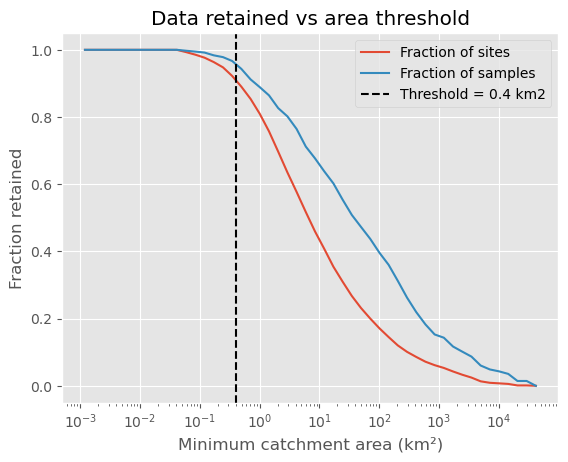

In [78]:
# Plot to explore impact of different thresholds
plot_df = pts_gdf_v3.copy()

thresholds = np.logspace(np.log10(plot_df.area_km2.min()), np.log10(plot_df.area_km2.max()), 50)

frac_sites = []
frac_samples = []

total_sites = len(plot_df)
total_samples = plot_df["n_samples"].sum()

for t in thresholds:
    subset = plot_df[plot_df["area_km2"] >= t]
    frac_sites.append(len(subset) / total_sites)
    frac_samples.append(subset["n_samples"].sum() / total_samples)

plt.figure()
plt.semilogx(thresholds, frac_sites, label="Fraction of sites")
plt.semilogx(thresholds, frac_samples, label="Fraction of samples")
plt.axvline(x=0.4, color='k', linestyle='--', label='Threshold = 0.4 km2')
plt.xlabel("Minimum catchment area (km²)")
plt.ylabel("Fraction retained")
plt.legend()
plt.title("Data retained vs area threshold")
plt.show()

i.e. a threshold of 0.4 involves dropping around 10% of sites and around 5% of samples (very roughly). i.e. more sites than samples, suggesting a lot of small sites without many samples.

In [79]:
# Explore - catchments with lots of data but small? N.B. also good last QC check for big rivers with bad delineation
# (Manually went through each of these)

tmp_df = pts_gdf_v3.loc[
    (pts_gdf_v3['n_samples'] >= 50) &
    (pts_gdf_v3['area_km2'] < 1)
]

with pd.option_context('display.max_rows', 100):
    display(tmp_df)

,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2_v1,is_lake_raw_v1,min_area_km2,delineate_v2,geometry,delineate_v3,area_km2
site_code,,,,,,,,,,,,,,,,
002-62914,11.085358,59.996670,62914,Bølerbekken BØL,2011,2025,14.7,154,10.48,0.574183,False,0.2,False,POINT (281713.333 6657501.885),False,0.574183
002-62942,10.555036,60.712542,62942,Bradalsmyra,2011,2025,10.4,62,5.93,0.203869,False,0.2,True,POINT (257547.9 6738978.2),False,0.051167
002-80335,11.155386,59.834584,80335,Bekk nedstrøms Flateby RA,2015,2025,10.1,68,6.73,0.425054,False,0.2,False,POINT (284566.8 6639242),False,0.425054
002-84236,10.544908,60.703166,84236,Bradalsmyra,2016,2025,9.5,51,7.34,0.677157,False,0.2,False,POINT (256925.197 6737973.04),False,0.677157
012-41899,9.730916,60.370935,41899,"Langtjern, innløpsbekk øst",1982,2017,35.2,1062,30.15,0.819771,False,0.2,False,POINT (209608.6 6704341.4),False,0.819771
012-81461,9.698617,59.660411,81461,Fiskumelva bekkefelt (st. 3A),2013,2019,5.8,80,13.89,0.725790,False,0.2,False,POINT (201484.967 6625524.712),False,0.725390
013-28681,10.278563,59.689013,28681,"Lerpebekken, oppstrøms Lindum avfallsanlegg",1988,2025,37.7,52,2.00,0.260959,False,0.2,False,POINT (234329.2 6626236.1),False,0.260959
014-64238,10.307570,59.226746,64238,Grimestad delfelt,1992,2002,10.3,306,29.62,0.314898,False,0.2,False,POINT (232326.401 6574726.53),False,0.314898
015-28508,10.020055,59.070657,28508,Gopledalsbekken,1994,2025,31.0,120,3.87,0.730731,False,0.2,False,POINT (214646.794 6558567.552),False,0.730731


In [80]:
# Drop any sites that persistently fail to delineate correctly
drop_sites_bad_delineation = ['078-63938']  # rivers flowing inland... Delineating downstream network. Flat agricultural ditch. n=20 for TOC

lake_sites = ['056-106522']  # Small drinking water lake. A=0.3 km2, sampling point by shore so classified as outlet when actually lake. n=102 (mostly after 2024; nice high-freq dataset)

# Sites with small catchments, lots of data, but drop because of nature of site/catchment
drop_ponds_industry = [
    '020-103207',  # Dam 1, Sørlandsparken øst
    '020-103208',  # Dam 2, Sørlandsparken øst
    '020-103210',  # Langsvann, innløp. Also Sørlandsparken, flowing from culvert into a pond
    '015-32073',  # Vassvikbekken. Drains gravel/sediment piles
    '022-85053',  # Tagsbekken, down from road building. Step change could be due to road building
]

drop_li = drop_sites_bad_delineation + drop_ponds_industry + lake_sites

## Start making final point df

In [81]:
# Start making final point df

pts_gdf_final = pts_gdf_v3.copy()

# Drop points
pts_gdf_final['drop'] = False
pts_gdf_final.loc[pts_gdf_final.index.isin(drop_li), 'drop'] = True

# Check
print("sites to drop:", pts_gdf_final['drop'].sum())

# Drop
pts_gdf_final = pts_gdf_final.loc[pts_gdf_final['drop'] == False]

print(len(pts_gdf_v3))
print(len(pts_gdf_final))

sites to drop: 7
9316
9309


In [82]:
# Small catchments -> drop
drop_small_df = pts_gdf_final.loc[
    (pts_gdf_final['n_samples'] < 100) &
    (pts_gdf_final['area_km2'] < 0.4)
]

# Add flag to drop
pts_gdf_final.loc[pts_gdf_final.index.isin(drop_small_df.index), 'drop'] = True
print((pts_gdf_final['drop'] == True).sum())

drop_small_df

827


,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2_v1,is_lake_raw_v1,min_area_km2,delineate_v2,geometry,delineate_v3,area_km2,drop
site_code,,,,,,,,,,,,,,,,,
001-38856,11.359621,59.853254,38856,"Viketjenn, utløp",2005,2024,19.0,19,1.00,1.820401,True,0.2,True,POINT (296117.534 6640672.357),False,0.071184,False
001-42062,11.404314,59.870829,42062,"Aurkytetjenn (ved Tunnsjøen), utløp",2007,2014,7.0,2,0.28,0.276347,True,0.2,False,POINT (298725.2 6642490.9),False,0.276347,False
001-42064,11.352583,59.873147,42064,Nordre Halstjenn v/Røyskollen,2007,2007,1.0,1,1.00,0.266342,True,0.2,False,POINT (295845.624 6642907.223),False,0.266342,False
001-48333,11.489173,58.890788,48333,Svendstjern,2011,2011,1.0,1,1.00,0.227953,False,0.2,True,POINT (297715.542 6533200.06),False,0.227953,False
001-48357,11.593958,59.013004,48357,"Åletjern, utløp",2020,2020,1.0,1,1.00,0.201972,False,0.2,True,POINT (304442.969 6546485.312),False,0.196373,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
246-103015,29.938335,69.640030,103015,"Langfjordtunnellen, utløp",2019,2025,6.1,5,3.00,0.366517,False,0.2,True,POINT (1075035.1 7796508.1),False,0.366517,False
307-124122,13.551702,64.888300,124122,43001 Ingeborgbekk,2025,2025,1.0,2,2.00,0.321420,False,0.2,False,POINT (431422.691 7196790.797),False,0.321420,False
313-55854,12.496986,60.179752,55854,Snustjennet,2008,2018,10.4,7,0.67,0.282493,True,0.2,False,POINT (361168.079 6674061.578),False,0.282493,False


In [83]:
# Small catchments, check out which are kept
keep_small_df = pts_gdf_final.loc[
    (pts_gdf_final['n_samples'] >= 100) &
    (pts_gdf_final['area_km2'] < 0.4)
]

keep_small_df

,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2_v1,is_lake_raw_v1,min_area_km2,delineate_v2,geometry,delineate_v3,area_km2,drop
site_code,,,,,,,,,,,,,,,,,
014-64238,10.30757,59.226746,64238,Grimestad delfelt,1992,2002,10.3,306,29.62,0.314898,False,0.2,False,POINT (232326.401 6574726.53),False,0.314898,False


In [84]:
# Drop small and data poor from pts_gdf_final and make cat_gdf_final

# Check
print("sites to drop:", pts_gdf_final['drop'].sum())
print("Sites before removing small catchs:", len(pts_gdf_final))

# Drop
pts_gdf_final = pts_gdf_final.loc[pts_gdf_final['drop'] == False]

print("Sites remaining:", len(pts_gdf_final))

sites to drop: 827
Sites before removing small catchs: 9309
Sites remaining: 8482


In [85]:
# Tidy up column names
drop_cols = ['area_km2_v1', 'min_area_km2', 'delineate_v2', 'delineate_v3', 'drop']
rename_cols = {'is_lake_raw_v1': 'pt_in_lake'}

pts_gdf_final = pts_gdf_final.drop(drop_cols, axis=1)
pts_gdf_final = pts_gdf_final.rename(rename_cols, axis=1)

pts_gdf_final

,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,pt_in_lake,geometry,area_km2
site_code,,,,,,,,,,,,
001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00,False,POINT (310465.118 6597884.57),1008.505005
001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00,False,POINT (310481.985 6597412.97),1009.065359
001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00,False,POINT (295802 6553328.19),6.702626
001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17,False,POINT (287981.65 6559432.015),15.372746
001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00,False,POINT (300536.51 6543885.23),42.290760
...,...,...,...,...,...,...,...,...,...,...,...,...
313-99151,12.111818,59.990523,99151,Hesbølsjøen utløp,2024,2024,1.0,5,5.00,True,POINT (338891.951 6653873.121),141.833882
314-46646,11.699073,59.634394,46646,"Åkevannet, utløp",2011,2022,11.0,4,0.36,False,POINT (313904.627 6615322.861),8.233540
314-48074,11.924796,59.747409,48074,"Røvatnet, utløp",2011,2011,1.0,1,1.00,False,POINT (327207.229 6627288.311),34.437679


In [86]:
cat_gdf_final = cat_gdf_v3.copy()

cat_gdf_final = cat_gdf_final.loc[cat_gdf_final.index.isin(pts_gdf_final.index), :]
cat_gdf_final = cat_gdf_final.drop('area_km2_v1', axis=1)

# Quick QC

# Same number of rows
assert len(cat_gdf_final) == len(pts_gdf_final), "Row count mismatch"

# Same index (both values and order)
assert cat_gdf_final.index.equals(pts_gdf_final.index), "Index mismatch"


# Same number of rows
assert len(cat_gdf_final) == len(pts_gdf_final), "Row count mismatch"

# Same index (both values and order)
assert cat_gdf_final.index.equals(pts_gdf_final.index), "Index mismatch"

cat_gdf_final

,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,geometry,area_km2
site_code,,,,,,,,,,,
001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00,"POLYGON ((306680 6664180, 306760 6664180, 3067...",1008.505005
001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00,"POLYGON ((306680 6664180, 306760 6664180, 3067...",1009.065359
001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00,"POLYGON ((298520 6555300, 298640 6555300, 2986...",6.702626
001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17,"POLYGON ((290660 6567260, 290680 6567260, 2906...",15.372746
001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00,"POLYGON ((305560 6548480, 305560 6548500, 3055...",42.290760
...,...,...,...,...,...,...,...,...,...,...,...
313-99151,12.111818,59.990523,99151,Hesbølsjøen utløp,2024,2024,1.0,5,5.00,"POLYGON ((330620 6675880, 330820 6675880, 3308...",141.833882
314-46646,11.699073,59.634394,46646,"Åkevannet, utløp",2011,2022,11.0,4,0.36,"POLYGON ((313080 6620240, 313120 6620240, 3131...",8.233540
314-48074,11.924796,59.747409,48074,"Røvatnet, utløp",2011,2011,1.0,1,1.00,"POLYGON ((323300 6634700, 323280 6634700, 3232...",34.437679


# Check for duplicate catchment geometries

I already checked for duplicate monitoring point locations, and all were different (although some were very close). So duplicates catchment boundaries means either:

1) Something went wrong with the delineation, so that points that should be in different places were snapped together
2) Slightly different monitoring points on the same channel, so essentially they are duplicates for our purposes.

Process below was to:
- Find duplicates (originally was 46 groups, mostly just 2/group, one group with 3). That was a small enough number that I then:
- Manually cross-check chem against Vannmiljø:
    * In a couple of cases, n is high enough, and the duplicate was wrong (i.e. one should have been one one fork, the other on another), that decide to redo the delineation. Add this info to the manual excel QC sheet v2.
    * In quite a few cases, the duplicate is because one or both of the sites has a mistaken boundary (often because of the minimum area threshold), i.e. it should have been a tiny insignificant channel but instead classed as the main one. Delete these. Manually add this "drop" info into the manual excel QC sheet v2.
    * Randomly spotted a couple of other sites to drop altogether - add these to the QC sheet v2 too

This flagging process included "low priority" sites (i.e. low n_samples), with the aim of getting rid of all duplicates that aren't genuine duplicates. Then that gives me the option later of merging data more easily. Though given there aren't that many duplicates, probably I just run with all the catchment processing without worrying about them for now.

Result after dropping additional sites was 28 "duplicate" geometries.

In [88]:
# Find duplicates
duplicates = cat_gdf_final.reset_index()[['site_code', 'lon', 'lat', 'Name', 'area_km2', 'n_samples', 'geometry']].copy()
duplicates['is_duplicate'] = duplicates.duplicated(subset='geometry', keep=False)

duplicates = duplicates[duplicates['is_duplicate']]

grouped_duplicates = duplicates.groupby('geometry')

print(len(grouped_duplicates))

28


In [28]:
# # Look at the groups
# for geom, group in grouped_duplicates:
#     display(group)
#     print("\n")

# Flag cross-border catchments

In [89]:
# 'norway_nve_regine_catchments_poly'

# Read countries
country_gdf = nivapy.da.read_postgis('cultural', 'world_nat_earth_10m_countries_poly', eng)[['name', 'geom']]

# Keep only relevant countries
country_gdf = country_gdf.loc[country_gdf['name'].isin(['Norway', 'Sweden', 'Finland', 'Russia'])]

country_gdf = country_gdf.rename(columns={'geom': 'geometry'})
country_gdf = country_gdf.set_geometry('geometry')
country_gdf = country_gdf.to_crs(cat_gdf_final.crs)

country_gdf

,name,geometry
29,Norway,"MULTIPOLYGON (((724254.32 7668702.403, 713959...."
50,Russia,"MULTIPOLYGON (((5178717.133 8402458.664, 51761..."
55,Sweden,"MULTIPOLYGON (((724254.32 7668702.403, 726522...."
56,Finland,"MULTIPOLYGON (((1053274.632 7720704.909, 10496..."


In [90]:
# Clean geometries before overlay
cat_gdf_final["geometry"] = cat_gdf_final.buffer(0)
country_gdf["geometry"] = country_gdf.buffer(0)


# Intersections with all countries
intersections = gpd.overlay(
    cat_gdf_final.reset_index()[["site_code", "geometry"]],
    country_gdf[["name", "geometry"]],
    how="intersection"
)

# Computer area in km2
intersections["country_area_km2"] = intersections.geometry.area / 1e6  # km2

# Sum area per (site_code, country)
area_by_country = (
    intersections
    .groupby(['site_code', 'name'])['country_area_km2']
    .sum()
    .unstack(fill_value=0)
)

# Ensure all columns exist
for c in ['Norway', 'Sweden', 'Finland', 'Russia']:
    if c not in area_by_country.columns:
        area_by_country[c] = 0

area_by_country = area_by_country[['Norway', 'Sweden', 'Finland', 'Russia']]

area_by_country.head()

name,Norway,Sweden,Finland,Russia
site_code,,,,
001-119928,998.430992,10.191408,0.0,0.0
001-119929,998.991392,10.191408,0.0,0.0
001-30653,6.704000,0.000000,0.0,0.0
001-30683,15.377200,0.000000,0.0,0.0
001-30687,42.297200,0.000000,0.0,0.0


In [91]:
# --- Join back to catchments ---
cat_gdf_final_foreignflag = cat_gdf_final.copy()

cat_gdf_final_foreignflag = cat_gdf_final_foreignflag.join(area_by_country, how='left').fillna(0)


# --- Convert to fractions ---

country_cols = ['Norway', 'Sweden', 'Finland', 'Russia']
total_intersection = cat_gdf_final_foreignflag[country_cols].sum(axis=1)

frac_col_li = []
for country in country_cols:
    col_name = f'frac_{country.lower()[:2]}'
    frac_col_li.append(col_name)

    # cat_gdf_final_foreignflag[col_name] = cat_gdf_final_foreignflag[country] / cat_gdf_final_foreignflag['area_km2']
    cat_gdf_final_foreignflag[col_name] = (cat_gdf_final_foreignflag[country] / total_intersection)

# Recompute outside Norway
frac_col_li.remove('frac_no')
sum_foreign_fracs = cat_gdf_final_foreignflag[frac_col_li].sum(axis=1)
cat_gdf_final_foreignflag['frac_outside_no'] =  sum_foreign_fracs

frac_col_li.append('frac_outside_no')


# Push to pts_gdf
# Join columns
pts_gdf_final = pts_gdf_final.join(
    cat_gdf_final_foreignflag[frac_col_li],
    how='left'
)

pts_gdf_final.head()

,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,pt_in_lake,geometry,area_km2,frac_sw,frac_fi,frac_ru,frac_outside_no
site_code,,,,,,,,,,,,,,,,
001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00,False,POINT (310465.118 6597884.57),1008.505005,0.010104,0.0,0.0,0.010104
001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00,False,POINT (310481.985 6597412.97),1009.065359,0.010099,0.0,0.0,0.010099
001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00,False,POINT (295802 6553328.19),6.702626,0.000000,0.0,0.0,0.000000
001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17,False,POINT (287981.65 6559432.015),15.372746,0.000000,0.0,0.0,0.000000
001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00,False,POINT (300536.51 6543885.23),42.290760,0.000000,0.0,0.0,0.000000


In [92]:
# Explore stats for sites with > 25% of the delineated catchment outside Norway

for frac in frac_col_li:
    frac_sites_li = pts_gdf_final.loc[pts_gdf_final[frac] > 0.25]
    print("-----------")
    print(f"{frac}: {len(frac_sites_li)} sites")
    print("")
    print(frac_sites_li[['area_km2'] + frac_col_li].describe().round(3))

-----------
frac_sw: 21 sites

       area_km2  frac_sw  frac_fi  frac_ru  frac_outside_no
count    21.000   21.000     21.0     21.0           21.000
mean    181.417    0.609      0.0      0.0            0.609
std     276.512    0.251      0.0      0.0            0.251
min       1.341    0.266      0.0      0.0            0.266
25%      15.158    0.338      0.0      0.0            0.338
50%     120.354    0.580      0.0      0.0            0.580
75%     212.225    0.829      0.0      0.0            0.829
max    1028.699    1.000      0.0      0.0            1.000
-----------
frac_fi: 12 sites

        area_km2  frac_sw  frac_fi  frac_ru  frac_outside_no
count     12.000     12.0   12.000     12.0           12.000
mean   11374.319      0.0    0.395      0.0            0.395
std     5874.105      0.0    0.241      0.0            0.241
min      772.489      0.0    0.251      0.0            0.251
25%    10132.413      0.0    0.300      0.0            0.300
50%    14878.611      0.0    0.3

# Save

Only keep foreign country flagging in pt_gdf.

In [93]:
# For saving
pts_gdf_final = pts_gdf_final.reset_index()
cat_gdf_final = cat_gdf_final.reset_index()

# Monitoring points

# As geopackage
final_pts_gpkg_fpath = os.path.join(cur_dir, "outlet_locations_vm-rivs-quant-oc_v3-full.gpkg")
pts_gdf_final.to_file(final_pts_gpkg_fpath, driver="GPKG", index=False)

# As csv
pts_final_df = pts_gdf_final.drop('geometry', axis=1)
final_pts_fpath = os.path.join(cur_dir, "outlet_locations_vm-rivs-quant-oc_v3-full.csv")
pts_final_df.to_csv(final_pts_fpath, index=False)

# Catchment boundaries
final_catchs_fpath = os.path.join(cur_dir, "catchments_vm-rivs-quant-oc_v3-full.gpkg")
cat_gdf_final.to_file(final_catchs_fpath, driver="GPKG", index=False)

# Quick look at "final" metadata

Further changes expected as this is the union of sites with either/and DOC and TOC data...

In [95]:
pts_gdf_final.describe()

,lon,lat,site_id,start_year,end_year,n_years,n_samples,av_freq,area_km2,frac_sw,frac_fi,frac_ru,frac_outside_no
count,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8375.000000,8375.000000,8375.000000,8482.000000
mean,9.913985,61.265743,79832.116954,2015.319854,2019.151026,4.359785,19.646899,3.851870,371.046094,0.002543,0.000668,0.000402,0.003567
std,3.602953,2.740834,29453.977219,8.567172,7.128063,6.207766,81.779150,7.389164,2071.385570,0.034275,0.017614,0.012576,0.040312
min,4.693305,58.018357,-11.000000,1980.000000,1983.000000,1.000000,1.000000,0.060000,0.314898,0.000000,0.000000,0.000000,0.000000
25%,7.706517,59.579832,56484.250000,2013.000000,2017.000000,1.000000,2.000000,1.000000,2.223637,0.000000,0.000000,0.000000,0.000000
50%,9.952011,60.361049,84850.000000,2017.000000,2021.000000,1.000000,4.500000,2.170000,8.748207,0.000000,0.000000,0.000000,0.000000
75%,10.999183,61.942946,103955.750000,2021.000000,2024.000000,5.700000,12.000000,4.530000,51.573524,0.000000,0.000000,0.000000,0.000000
max,30.952229,70.962425,127364.000000,2025.000000,2026.000000,44.900000,2020.000000,246.040000,41698.280949,1.000000,1.000000,0.572790,1.000000


i.e.
* 8482 sites left (out of an original 10,800'ish)
* Area now has an IQR of around 2 to 50 km2 (median just under 9 km2)
* Most data concentrated around 2013-2024 still
* Most sites (IQR) have between 2 and 12 samples -> will try ML with and without low-n sites

Probably a tonne of them are heavily overlapping, but won't look into that now.

**To do:** Add vassdragsområde as a metadata column. But will require a little bit of manual work for nearly-marine sites that don't have vassdragsområde prefix to the site code (manually add vassom for those). Will be interesting to look at counts per vassdragsområde, perhaps normalised by vassdragsområde area. Will also be a good way of doing regional cross-validation.

# Quick reload check

In [5]:
final_pts_gpkg_fpath = os.path.join(cur_dir, "outlet_locations_vm-rivs-quant-oc_v3-full.gpkg")
final_pts_fpath = os.path.join(cur_dir, "outlet_locations_vm-rivs-quant-oc_v3-full.csv")
final_catchs_fpath = os.path.join(cur_dir, "catchments_vm-rivs-quant-oc_v3-full.gpkg")

# --- Reload files ---
pts_gdf_reload = gpd.read_file(final_pts_gpkg_fpath)
cat_gdf_reload = gpd.read_file(final_catchs_fpath)
pts_csv_reload = pd.read_csv(final_pts_fpath)

# --- Basic checks ---
print("Points GPKG rows:", len(pts_gdf_reload))
print("Points CSV rows:", len(pts_csv_reload))
print("Catchments GPKG rows:", len(cat_gdf_reload))

# --- Column checks ---
cols = ['lat', 'lon', 'area_km2']

print("\nColumn consistency (GeoPackage vs CSV):")
for col in cols:
    match = np.allclose(
        pts_gdf_reload[col],
        pts_csv_reload[col],
        rtol=1e-6,
        atol=1e-8,
        equal_nan=True
    )
    print(f"{col}: {match}")

# --- Geometry sanity check ---
print("\nGeometry type:", pts_gdf_reload.geometry.geom_type.unique())
print("CRS:", pts_gdf_reload.crs)

# --- Optional: reconstruct GeoDataFrame from CSV ---
pts_from_csv = gpd.GeoDataFrame(
    pts_csv_reload,
    geometry=gpd.points_from_xy(pts_csv_reload.lon, pts_csv_reload.lat),
    crs="EPSG:4326"
)
pts_from_csv = pts_from_csv.to_crs(pts_gdf_reload.crs)

print("Same index order:", pts_gdf_reload.index.equals(pts_from_csv.index))

# Compare geometries (tolerant)
geom_match = (
    np.allclose(
        pts_gdf_reload.geometry.x,
        pts_from_csv.geometry.x,
        rtol=1e-6,
        atol=1e-8
    )
    and
    np.allclose(
        pts_gdf_reload.geometry.y,
        pts_from_csv.geometry.y,
        rtol=1e-6,
        atol=1e-8
    )
)

print("\nGeometry reconstructed from CSV matches:", geom_match)

print("Reload CRS:", pts_gdf_reload.crs)

Points GPKG rows: 8482
Points CSV rows: 8482
Catchments GPKG rows: 8482

Column consistency (GeoPackage vs CSV):
lat: True
lon: True
area_km2: True

Geometry type: ['Point']
CRS: EPSG:25833
Same index order: True

Geometry reconstructed from CSV matches: True
Reload CRS: EPSG:25833


In [7]:
pts_gdf_reload.head()

,index,site_code,longitude,latitude,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,pt_in_lake,area_km2,frac_sw,frac_fi,frac_ru,frac_outside_no,geometry
0,0,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00,False,1008.505005,0.010104,0.0,0.0,0.010104,POINT (310465.118 6597884.57)
1,1,001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00,False,1009.065359,0.010099,0.0,0.0,0.010099,POINT (310481.985 6597412.97)
2,2,001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00,False,6.702626,0.000000,0.0,0.0,0.000000,POINT (295802 6553328.19)
3,3,001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17,False,15.372746,0.000000,0.0,0.0,0.000000,POINT (287981.65 6559432.015)
4,4,001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00,False,42.290760,0.000000,0.0,0.0,0.000000,POINT (300536.51 6543885.23)


In [8]:
# Plot location of all sites
pts_gdf_reload = pts_gdf_reload.to_crs("EPSG:25833")

pts_gdf_reload = pts_gdf_reload.rename({'lon': 'longitude', 'lat': 'latitude'}, axis=1).reset_index()

print(len(pts_gdf_reload), "River stations in Norway with OC data")
nivapy.spatial.quickmap(
    pts_gdf_reload, kartverket=True, popup='site_code', aerial_imagery=False
)

8482 River stations in Norway with OC data
